# Sentiment analysis on movie reviews

The question for this notebook: given the text of a movie review, can we tell whether the reviewer liked the film?

The data is NLTK's `movie_reviews` corpus, 2,000 IMDb reviews collected by Pang & Lee (2004) and labelled positive or negative. I'll work through it in steps:

1. load the corpus and take a first look
2. explore it: class balance, review lengths, the words people use
3. a lexicon baseline (VADER) that needs no training
4. bag-of-words and TF-IDF models
5. tuning and comparing them
6. looking at the reviews the best model still gets wrong

## 1. Setup and loading the data

In [1]:
import sys
from pathlib import Path

import nltk
import pandas as pd

# the helpers live in the repo root, next to this notebook
sys.path.insert(0, str(Path.cwd()))
from sentiment.data import load_reviews

pd.set_option("display.max_colwidth", 120)
print("nltk", nltk.__version__, "| pandas", pd.__version__)

nltk 3.10.4 | pandas 3.0.5


In [2]:
df = load_reviews()
print(df.shape)
df.head()

(2000, 3)


,fileid,label,text
0,neg/cv000_29416.txt,neg,"plot : two teen couples go to a church party , drink and then drive . \nthey get into an accident . \none of the guy..."
1,neg/cv001_19502.txt,neg,the happy bastard's quick movie review \ndamn that y2k bug . \nit's got a head start in this movie starring jamie le...
2,neg/cv002_17424.txt,neg,it is movies like these that make a jaded movie viewer thankful for the invention of the timex indiglo watch . \nbas...
3,neg/cv003_12683.txt,neg,""" quest for camelot "" is warner bros . ' first feature-length , fully-animated attempt to steal clout from disney's..."
4,neg/cv004_12641.txt,neg,synopsis : a mentally unstable man undergoing psychotherapy saves a boy from a potentially fatal accident and then f...


Each review is stored in its own file, and the file id already says which class it's in (`neg/cv000_29416.txt`). The label column comes from those folders, nothing was annotated by me.

In [3]:
df["label"].value_counts()

label
neg    1000
pos    1000
Name: count, dtype: int64

Exactly 1,000 of each, so accuracy is a fair metric here and a model that always guesses one class scores 50%. That's the floor every model has to beat.

What does a review actually look like?

In [4]:
sample = df.sample(2, random_state=7)
for _, row in sample.iterrows():
    print(f"[{row.label}] {row.fileid}")
    print(row.text[:700], "...\n")

[pos] pos/cv072_6169.txt
the long kiss goodnight ( r ) meryl streep tried it and failed . 
even pamela anderson lee made an attempt but fell flat on her well-bared assets . 
however , geena davis could very well become the first bankable american female action star with the long kiss goodnight , a preposterous but incredibly fun action thriller directed by her husband , renny harlin . 
davis plays samantha caine , a mousy suburban school teacher and mother whose memories only go back eight years . 
with the help of ethically questionable private detective mitch hennessey ( samuel l . jackson ) , she slowly remembers--and reclaims--her past as charly baltimore , tough-as-nails cia operative . 
needless to say , with  ...

[pos] pos/cv048_16828.txt
when _star wars_ came out some twenty years ago , the image of traveling throughout the stars has become a commonplace image . 
when the millenium falcon moves throughout the stars , we see constellations , meteor showers , and cool space-ship

A few things stand out already:

- the text is **lowercased and pre-tokenized**: punctuation is split off into its own tokens (`drive .`, `( r )`), so there's no capitalisation or formatting to use as a signal
- reviews are **long** and mostly plot summary; the actual opinion is often a couple of sentences, sometimes only at the end
- reviewers **mix praise and criticism** in one breath ("a preposterous but incredibly fun action thriller"), which will be hard for anything that just counts words

The corpus also comes with NLTK's own tokenization, which I'll use instead of splitting the raw text again:

In [5]:
from nltk.corpus import movie_reviews

words = movie_reviews.words(df.fileid[0])
print(len(words), "tokens in the first review")
print(words[:40])

879 tokens in the first review
['plot', ':', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', ',', 'drink', 'and', 'then', 'drive', '.', 'they', 'get', 'into', 'an', 'accident', '.', 'one', 'of', 'the', 'guys', 'dies', ',', 'but', 'his', 'girlfriend', 'continues', 'to', 'see', 'him', 'in', 'her', 'life', ',', 'and']


In [6]:
vocab = {w for fid in df.fileid for w in movie_reviews.words(fid)}
total_tokens = sum(len(movie_reviews.words(fid)) for fid in df.fileid)
print(f"{total_tokens:,} tokens, {len(vocab):,} distinct")

1,583,820 tokens, 39,768 distinct


Around 1.6 million tokens over 2,000 reviews, so about 790 per review on average. That's a lot more text per example than tweets or product one-liners, and the next section looks at how much the lengths vary.

## 2. Exploring the data

### Review lengths

Do positive and negative reviews differ in length? If one class were much longer, a model could pick that up instead of the actual sentiment, so it's worth checking before training anything.

In [7]:
import matplotlib.pyplot as plt
import numpy as np

from sentiment.data import ensure_corpus

ensure_corpus("punkt_tab", kind="tokenizers")  # .sents() splits sentences with punkt

df["tokens"] = [list(movie_reviews.words(fid)) for fid in df.fileid]
df["n_tokens"] = df["tokens"].str.len()
df["n_sentences"] = [len(movie_reviews.sents(fid)) for fid in df.fileid]

df.groupby("label")[["n_tokens", "n_sentences"]].describe().round(1).T

label                 neg     pos
n_tokens    count  1000.0  1000.0
            mean    751.3   832.6
            std     315.4   372.3
            min      19.0   144.0
            25%     543.0   575.8
            50%     707.0   779.5
            75%     905.2  1011.0
            max    2339.0  2879.0
n_sentences count  1000.0  1000.0
            mean     35.5    36.0
            std      18.8    16.6
            min       1.0     5.0
            25%      23.0    25.0
            50%      32.0    33.0
            75%      43.0    44.0
            max     188.0   127.0

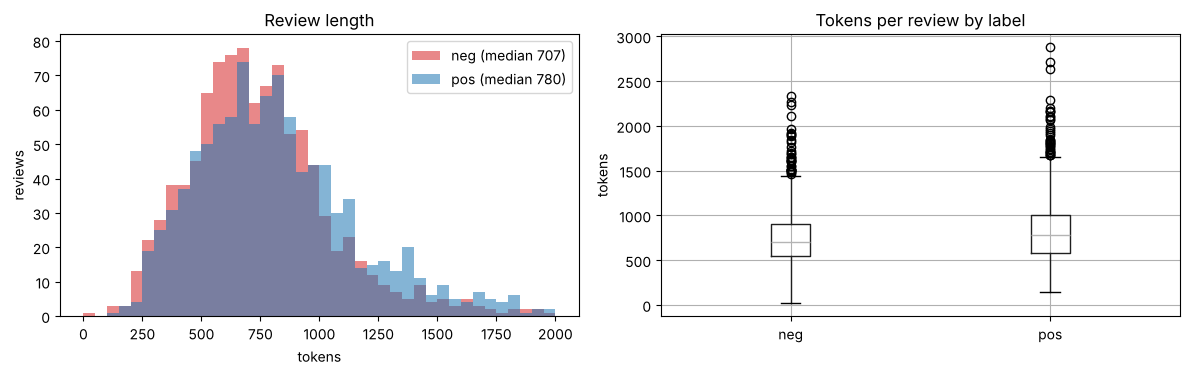

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 2000, 41)
for label, color in [("neg", "tab:red"), ("pos", "tab:blue")]:
    lengths = df.loc[df.label == label, "n_tokens"]
    name = f"{label} (median {lengths.median():.0f})"
    axes[0].hist(lengths, bins=bins, alpha=0.55, color=color, label=name)
axes[0].set(title="Review length", xlabel="tokens", ylabel="reviews")
axes[0].legend()

df.boxplot(column="n_tokens", by="label", ax=axes[1], showfliers=True)
axes[1].set(title="Tokens per review by label", xlabel="", ylabel="tokens")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import mannwhitneyu

neg_len = df.loc[df.label == "neg", "n_tokens"]
pos_len = df.loc[df.label == "pos", "n_tokens"]
result = mannwhitneyu(pos_len, neg_len)
print(f"median tokens: pos {pos_len.median():.0f}, neg {neg_len.median():.0f}")
print(f"Mann-Whitney U p-value: {result.pvalue:.2g}")

median tokens: pos 780, neg 707
Mann-Whitney U p-value: 2.9e-06


Positive reviews run a bit longer: a median of about 780 tokens against 707 for negative ones, and the gap is
very unlikely to be chance (Mann-Whitney p ≈ 3e-6). Sentence counts are almost identical, so the difference comes
from longer sentences rather than more of them. The distributions overlap heavily though, so length on its own
would be a weak feature. It's a hint that reviewers who liked a film say more about it, not something a model
can lean on.

### Most common words

Raw counts first, then with English stopwords and punctuation removed.

In [10]:
from collections import Counter

from nltk.corpus import stopwords

ensure_corpus("stopwords")
stop = set(stopwords.words("english"))


def content_words(tokens):
    return [t for t in tokens if t.isalpha() and t not in stop]


raw_counts = Counter(t for toks in df.tokens for t in toks)
content_counts = {label: Counter() for label in ("neg", "pos")}
for label, toks in zip(df.label, df.tokens, strict=True):
    content_counts[label].update(content_words(toks))

pd.DataFrame({
    "raw": [w for w, _ in raw_counts.most_common(15)],
    "neg (content)": [w for w, _ in content_counts["neg"].most_common(15)],
    "pos (content)": [w for w, _ in content_counts["pos"].most_common(15)],
})

,raw,neg (content),pos (content)
0,",",film,film
1,the,movie,one
2,.,one,movie
3,a,like,like
4,and,even,good
5,of,time,story
6,to,good,time
7,',would,also
8,is,get,even
9,in,bad,well


### Words that separate the classes

Raw frequency mostly surfaces words both classes share ("film", "movie"). To find words that lean one way I use
the log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn 2008), which shrinks the scores
of rare words instead of letting a word seen twice dominate. Positive z-scores lean positive.

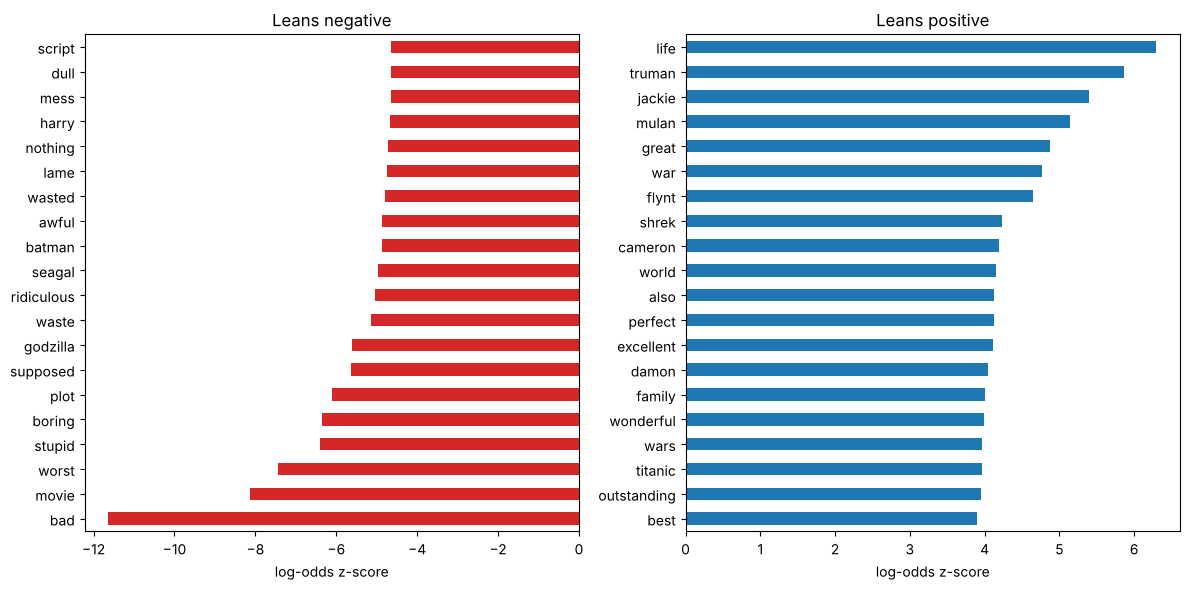

In [11]:
def log_odds(counts_a, counts_b, prior):
    a0, b0, p0 = sum(counts_a.values()), sum(counts_b.values()), sum(prior.values())
    rows = []
    for w, pw in prior.items():
        ya, yb = counts_a[w], counts_b[w]
        la = np.log((ya + pw) / (a0 + p0 - ya - pw))
        lb = np.log((yb + pw) / (b0 + p0 - yb - pw))
        var = 1 / (ya + pw) + 1 / (yb + pw)
        rows.append((w, (la - lb) / np.sqrt(var), ya, yb))
    return pd.DataFrame(rows, columns=["word", "z", "pos_count", "neg_count"]).set_index("word")


prior = content_counts["neg"] + content_counts["pos"]
scores = log_odds(content_counts["pos"], content_counts["neg"], prior).sort_values("z")
top_neg, top_pos = scores.head(20), scores.tail(20)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
top_neg.z.plot.barh(ax=axes[0], color="tab:red", title="Leans negative")
top_pos.z.plot.barh(ax=axes[1], color="tab:blue", title="Leans positive")
for ax in axes:
    ax.set(xlabel="log-odds z-score", ylabel="")
plt.tight_layout()
plt.show()

In [12]:
pd.concat([top_neg.head(10), top_pos.tail(10)[::-1]]).round(1)

,z,pos_count,neg_count
word,,,
bad,-11.6,361,1034
movie,-8.1,2525,3246
worst,-7.4,49,259
stupid,-6.4,45,208
boring,-6.3,52,218
plot,-6.1,596,917
supposed,-5.6,83,240
godzilla,-5.6,14,120
waste,-5.1,22,121


A few things stand out:

- With stopwords gone, the top of both lists is nearly the same ("film", "movie", "one", "like"), and "good" shows
  up high for negative reviews too (its z-score is about -0.7, so it is neutral). Frequency alone won't separate the classes.
- The negative side of the log-odds chart is clean sentiment vocabulary: "bad" (z ≈ -11.6, used about three times
  as often in negative reviews), "worst", "stupid", "boring", "waste", "ridiculous".
- "movie" leans negative (z ≈ -8.1) while "film" leans slightly positive (z ≈ 2.3). My guess is that people who
  dislike something call it a movie.
- The positive side is messier. Next to "great" and "life" it's full of titles and names: "truman", "mulan",
  "flynt", "shrek". Those films were well liked and reviewed more than once, so a bag-of-words model will learn
  "mentions Shrek → positive". That works on this corpus and generalises badly, which is worth remembering when
  the baseline scores come in.
- Negation is invisible here: "not good" counts as one "good". Handling that is one reason to try bigrams later.

## 3. A lexicon baseline (VADER)

### Holding out a test set first

Before any model, I set aside a quarter of the reviews as a test set, stratified so it stays 50/50. Every model
below is scored on these same 500 reviews, and anything that gets tuned is tuned on the other 1,500 only.

In [13]:
from sentiment.data import split_reviews

train, test = split_reviews(df)
print(len(train), "train /", len(test), "test")
test.label.value_counts()

1500 train / 500 test


label
pos    250
neg    250
Name: count, dtype: int64

### VADER out of the box

VADER (Hutto & Gilbert 2014) is a hand-built sentiment lexicon with rules for negation, intensifiers like "very"
and contrast words like "but". It needs no training, which makes it a useful baseline: anything trained on this
data should beat it. Its `compound` score runs from -1 to 1, and the usual rule is to call anything above 0
positive.

In [14]:
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, classification_report

ensure_corpus("vader_lexicon", kind="sentiment")
sia = SentimentIntensityAnalyzer()

for part in (train, test):
    part["vader"] = [sia.polarity_scores(t)["compound"] for t in part.text]

vader_pred = np.where(test.vader > 0, "pos", "neg")
print(f"VADER accuracy on the test set: {accuracy_score(test.label, vader_pred):.3f}")
print(classification_report(test.label, vader_pred, digits=3))

VADER accuracy on the test set: 0.650
              precision    recall  f1-score   support

         neg      0.725     0.484     0.580       250
         pos      0.613     0.816     0.700       250

    accuracy                          0.650       500
   macro avg      0.669     0.650     0.640       500
weighted avg      0.669     0.650     0.640       500



65% on the test set, so VADER is better than a coin flip but not by much. The report shows why: it finds 82% of
the positive reviews but only 48% of the negative ones. Half the negative reviews get a compound score above 0.

That fits what the EDA showed. Negative reviews still use plenty of positive words ("good", "like", praise for an
actor before the "but"), and VADER sums over the whole review. Over ~750 tokens those small positive cues add up,
and the compound score saturates: about 80% of test reviews land beyond ±0.9.

### A better threshold?

If VADER leans positive on everything, a higher cut-off than 0 might help. I pick the threshold that gives the best
accuracy on the training reviews, then check it once on the test set.

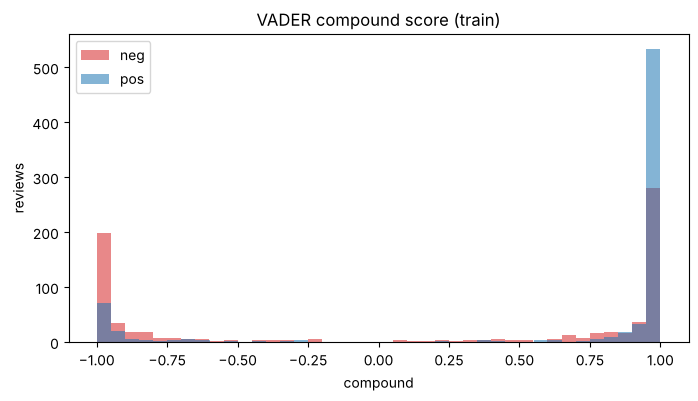

best threshold on train: 0.97 (train accuracy 0.681)
test accuracy with it:   0.690


In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, color in [("neg", "tab:red"), ("pos", "tab:blue")]:
    ax.hist(train.loc[train.label == label, "vader"], bins=40, alpha=0.55, color=color, label=label)
ax.set(title="VADER compound score (train)", xlabel="compound", ylabel="reviews")
ax.legend()
plt.show()

thresholds = np.linspace(-0.95, 0.99, 195)
train_acc = [accuracy_score(train.label, np.where(train.vader > t, "pos", "neg")) for t in thresholds]
best_t = thresholds[int(np.argmax(train_acc))]
tuned_pred = np.where(test.vader > best_t, "pos", "neg")
print(f"best threshold on train: {best_t:.2f} (train accuracy {max(train_acc):.3f})")
print(f"test accuracy with it:   {accuracy_score(test.label, tuned_pred):.3f}")

Moving the cut-off all the way up to 0.97 gives 68.1% on train and 69.0% on test, up from 65%. In practice the
tuned rule says "positive only if VADER is almost certain". That this works at all shows how far a whole-review
compound score saturates. This tuned VADER, at **69%**, is the number to beat. A lexicon can't learn that
"godzilla" or "supposed to be" signal a bad review on this corpus, and the models trained in the next section can.

## 4. Trained models

### Bag of words + Naive Bayes

The classic first model for text: count each word, then multinomial Naive Bayes. The pipeline lives in
`sentiment/models.py`. It splits on whitespace because the corpus is already tokenized, and it drops words seen in
fewer than two reviews. Besides the test score I also report 5-fold cross-validation on the training set, which
shows how much the score moves between splits.

In [16]:
from sklearn.model_selection import cross_val_score

from sentiment.models import bow_naive_bayes

results = {"VADER (threshold 0)": accuracy_score(test.label, vader_pred),
           f"VADER (threshold {best_t:.2f})": accuracy_score(test.label, tuned_pred)}

nb_model = bow_naive_bayes()
cv = cross_val_score(nb_model, train.text, train.label, cv=5)
nb_model.fit(train.text, train.label)
results["BoW + Naive Bayes"] = accuracy_score(test.label, nb_model.predict(test.text))
print(f"vocabulary: {len(nb_model.named_steps['vec'].vocabulary_):,} words")
print(f"5-fold CV on train: {cv.mean():.3f} ± {cv.std():.3f}")
print(f"test accuracy:      {results['BoW + Naive Bayes']:.3f}")

vocabulary: 22,907 words
5-fold CV on train: 0.813 ± 0.015
test accuracy:      0.812


81.2% on the test set, against 69% for the tuned VADER, and the cross-validation score (81.3% ± 1.5) agrees
with it, so this isn't a lucky split. Plain word counts and a model that assumes words are independent already do
much better than a hand-built lexicon, because the model learns this corpus's own vocabulary.

### TF-IDF + logistic regression

Next, the same tokens with TF-IDF weights (sublinear tf, so a word used ten times doesn't count ten times as much)
fed to logistic regression. Unlike Naive Bayes it doesn't assume words are independent, and the regularisation
keeps the 20k-odd weights in check. I use default settings here and leave tuning for the next section.

In [17]:
from sentiment.models import tfidf_logreg

lr_model = tfidf_logreg()
cv = cross_val_score(lr_model, train.text, train.label, cv=5)
lr_model.fit(train.text, train.label)
results["TF-IDF + logistic regression"] = accuracy_score(test.label, lr_model.predict(test.text))
print(f"5-fold CV on train: {cv.mean():.3f} ± {cv.std():.3f}")
print(f"test accuracy:      {results['TF-IDF + logistic regression']:.3f}")

5-fold CV on train: 0.855 ± 0.024
test accuracy:      0.860


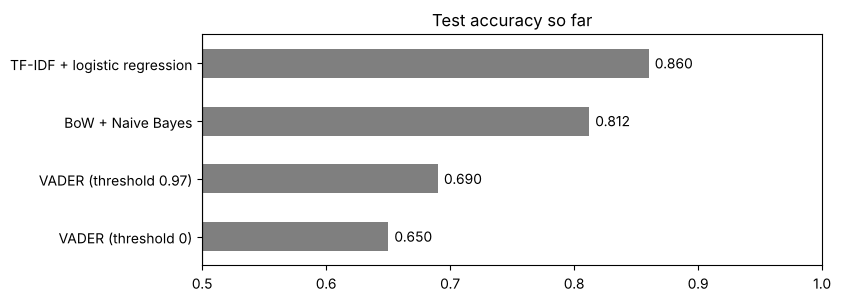

,test accuracy
VADER (threshold 0),0.650
VADER (threshold 0.97),0.690
BoW + Naive Bayes,0.812
TF-IDF + logistic regression,0.860


In [18]:
summary = pd.Series(results, name="test accuracy").sort_values()
ax = summary.plot.barh(figsize=(8, 3), color="tab:gray", xlim=(0.5, 1), title="Test accuracy so far")
ax.axvline(0.5, color="black", lw=0.8)
for i, v in enumerate(summary):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.show()
summary.round(3).to_frame()

TF-IDF with logistic regression reaches **86.0%** on the test set (85.5% ± 2.4 in cross-validation), the best so
far. That's 24 more of the 500 test reviews right than Naive Bayes. The test set is small, so the gap is less exact
than it looks: one review is 0.2 points, and the CV spread is about ±2. Still, both measurements put logistic
regression ahead.

Neither model has been tuned yet. The next section tries bigrams (to catch "not good"), different `min_df` and
regularisation, and then looks at what the best model actually learned.

## 5. Tuning and comparing

### A small grid search

For each model I search a few settings that matter for text: unigrams vs unigrams + bigrams, the `min_df`
cut-off, and the smoothing (`alpha`) or regularisation strength (`C`). Selection uses 5-fold cross-validation
on the training reviews only. The test set is scored once, with the chosen settings.

In [19]:
from sklearn.model_selection import GridSearchCV

grids = {
    "BoW + Naive Bayes (tuned)": (bow_naive_bayes(), {
        "vec__ngram_range": [(1, 1), (1, 2)],
        "vec__min_df": [1, 2, 5],
        "clf__alpha": [0.1, 0.5, 1.0],
    }),
    "TF-IDF + logistic regression (tuned)": (tfidf_logreg(), {
        "vec__ngram_range": [(1, 1), (1, 2)],
        "vec__min_df": [2, 5],
        "clf__C": [1.0, 10.0, 100.0],
    }),
}

searches, rows = {}, []
for name, (pipe, grid) in grids.items():
    search = GridSearchCV(pipe, grid, cv=5, n_jobs=-1).fit(train.text, train.label)
    searches[name] = search
    results[name] = accuracy_score(test.label, search.predict(test.text))
    rows.append({"model": name, "best settings": search.best_params_,
                 "CV accuracy": round(search.best_score_, 3), "test accuracy": round(results[name], 3)})
pd.DataFrame(rows).set_index("model")

,best settings,CV accuracy,test accuracy
model,,,
BoW + Naive Bayes (tuned),"{'clf__alpha': 1.0, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}",0.832,0.824
TF-IDF + logistic regression (tuned),"{'clf__C': 10.0, 'vec__min_df': 5, 'vec__ngram_range': (1, 1)}",0.879,0.868


In [20]:
# how much each setting matters for logistic regression, averaged over the others
cv_lr = pd.DataFrame(searches["TF-IDF + logistic regression (tuned)"].cv_results_)
for param in ["param_vec__ngram_range", "param_clf__C", "param_vec__min_df"]:
    print(cv_lr.groupby(param)["mean_test_score"].mean().round(3).to_dict())

{(1, 1): 0.871, (1, 2): 0.866}
{1.0: 0.855, 10.0: 0.874, 100.0: 0.875}
{2: 0.866, 5: 0.871}


Tuning helps both models, but not by much:

- **Naive Bayes** goes from 81.2% to 82.4%. It does best with bigrams added, which is what I hoped for: pairs like
  "not good" become their own feature.
- **Logistic regression** goes from 86.0% to 86.8% with weaker regularisation (`C=10`) and `min_df=5`. Here
  bigrams didn't help: averaged over the other settings, unigrams scored 87.1% in CV against 86.6% with bigrams.
  With only 1,500 training reviews the extra bigram features add more noise than signal for this model.
- The CV scores (83.2% and 87.9%) are a little higher than the test scores, which is normal after picking the
  best of 18 and 12 configurations on the same folds.

The full comparison:

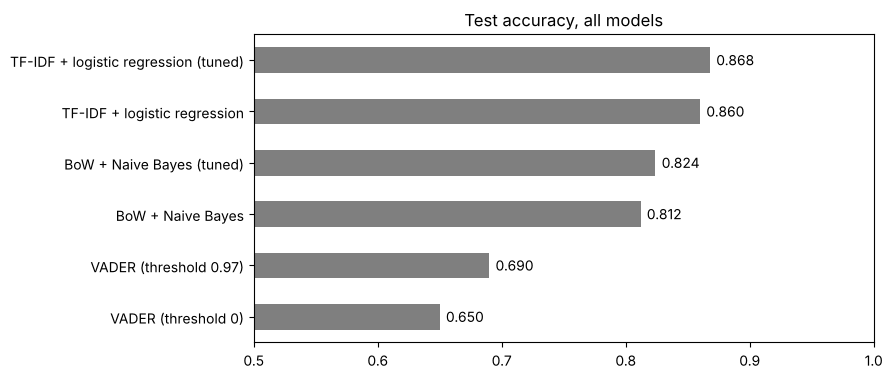

,test accuracy
VADER (threshold 0),0.650
VADER (threshold 0.97),0.690
BoW + Naive Bayes,0.812
BoW + Naive Bayes (tuned),0.824
TF-IDF + logistic regression,0.860
TF-IDF + logistic regression (tuned),0.868


In [21]:
summary = pd.Series(results, name="test accuracy").sort_values()
ax = summary.plot.barh(figsize=(8, 4), color="tab:gray", xlim=(0.5, 1), title="Test accuracy, all models")
for i, v in enumerate(summary):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.show()
summary.round(3).to_frame()

### The best model up close

Tuned TF-IDF + logistic regression is the best model, so the rest of the notebook looks at it. First, which way
does it go wrong?

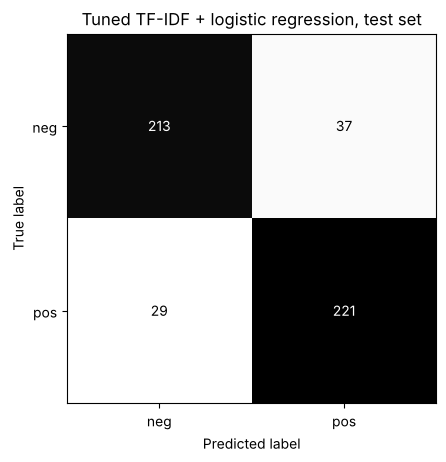

              precision    recall  f1-score   support

         neg      0.880     0.852     0.866       250
         pos      0.857     0.884     0.870       250

    accuracy                          0.868       500
   macro avg      0.868     0.868     0.868       500
weighted avg      0.868     0.868     0.868       500



In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

best = searches["TF-IDF + logistic regression (tuned)"].best_estimator_
test["pred"] = best.predict(test.text)
test["p_pos"] = best.predict_proba(test.text)[:, list(best.classes_).index("pos")]

ConfusionMatrixDisplay.from_predictions(test.label, test.pred, cmap="Greys", colorbar=False)
plt.title("Tuned TF-IDF + logistic regression, test set")
plt.show()
print(classification_report(test.label, test.pred, digits=3))

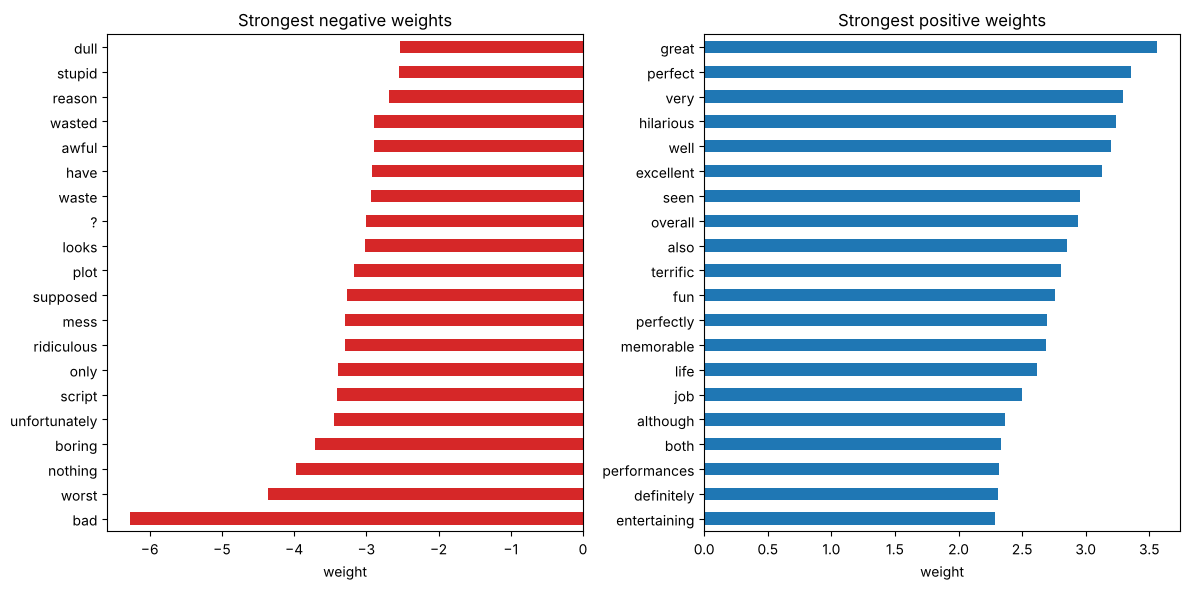

11,488 features


In [23]:
# the weights the model learned: positive weights push towards "pos"
vec, clf = best.named_steps["vec"], best.named_steps["clf"]
sign = 1 if clf.classes_[1] == "pos" else -1
weights = pd.Series(sign * clf.coef_[0], index=vec.get_feature_names_out()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
weights.head(20).plot.barh(ax=axes[0], color="tab:red", title="Strongest negative weights")
weights.tail(20).plot.barh(ax=axes[1], color="tab:blue", title="Strongest positive weights")
for ax in axes:
    ax.set(xlabel="weight", ylabel="")
plt.tight_layout()
plt.show()
print(f"{len(weights):,} features")

The errors are fairly balanced: 37 negative reviews called positive and 29 positive ones called negative. That's
a big change from VADER, which got half the negative reviews wrong.

The weights read sensibly:

- The negative side is the vocabulary from the EDA ("bad", "worst", "boring", "waste", "stupid"), plus a few
  telling extras: "unfortunately", "supposed" (as in "supposed to be funny"), "script" and "plot" (reviewers
  complain about these), and "?", since a disappointed reviewer asks rhetorical questions.
- The positive side mixes praise ("great", "perfect", "excellent", "terrific", "memorable") with words about
  craft ("performances", "job" as in "does a fine job").
- Words like "also", "both", "although" and "overall" lean positive. Reviewers who liked a film list more things
  about it, then sum up.
- The film titles that topped the log-odds list ("shrek", "mulan") don't appear in the top weights. `min_df=5`
  and the regularisation keep the model from leaning on names that only a few reviews mention.